### Facility Risk Model
This is the core predictive component. A Random Forest classifier is trained to predict — at the level of individual health centres — which facilities are most likely to be non-functional before the next disbursement cycle.

**BUILDING THE MODEL**

In [5]:
import pandas as pd
from pathlib import Path

OUT_DIR = Path(r"C:\Users\hp\Basic_healthcare_modelling_project\output")

facilities = pd.read_csv(OUT_DIR / "facilities.csv")
df_ml = pd.read_csv(OUT_DIR / "anomaly_results.csv")
state_features = pd.read_csv(OUT_DIR / "state_features.csv")


print(facilities.columns.tolist())
print(facilities["status"].value_counts())
print(facilities.shape)       # (8309, 5)
print(state_features.shape)   # (37, 18)

['state', 'lga', 'ward', 'facility', 'status']
status
L1                5397
L2                1747
PARTIAL           1164
NON-FUNCTIONAL       1
Name: count, dtype: int64
(8309, 5)
(37, 18)


We have a severe class imbalance problem.

L1              5,397  (65%),
L2              1,747  (21%),
PARTIAL         1,164  (14%),
NON-FUNCTIONAL      1  (0.01%).

Only 1 facility is labelled NON-FUNCTIONAL out of 8,309. That’s not enough to train on as a separate class — any model would simply ignore it.
So we’ll collapse the 4 statuses into a binary label:

AT RISK = 1 → PARTIAL or NON-FUNCTIONAL (1,165 facilities, ~14%),
FUNCTIONAL = 0 → L1 or L2 (7,144 facilities, ~86%).
This makes the model answer one clean question: which facilities are at risk of degrading to partial or non-functional before the next funding cycle?

In [6]:
# Build the Feature Table
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import numpy as np

# ── BINARY LABEL ───
# AT RISK = 1 → PARTIAL or NON-FUNCTIONAL
# FUNCTIONAL = 0 → L1 or L2
facilities["risk_label"] = facilities["status"].isin(
    ["PARTIAL", "NON-FUNCTIONAL"]
).astype(int)

print("Label distribution:")
print(facilities["risk_label"].value_counts())
print(f"At-risk rate: {facilities['risk_label'].mean():.1%}")

Label distribution:
risk_label
0    7144
1    1165
Name: count, dtype: int64
At-risk rate: 14.0%


**Join state-level features onto each facility**

In [7]:
# Each facility inherits its state's features.
# This gives the model context: a facility in a high-anomaly state
# is more likely to be at risk than one in a clean state.
fac_model = facilities.merge(state_features, on="state", how="left")
fac_model = fac_model.merge(
    df_ml[["state", "consensus_score", "iso_score", "lof_score"]], 
    on="state", how="left")

# Encode state and LGA as numbers — Random Forest needs numeric inputs
le_state = LabelEncoder()
le_lga   = LabelEncoder()
fac_model["state_enc"] = le_state.fit_transform(fac_model["state"])
fac_model["lga_enc"]   = le_lga.fit_transform(fac_model["lga"])

# Features for the model
FAC_FEATURES = [
    "state_enc",
    "lga_enc",
    "total_ytd",
    "ytd_per_facility",
    "ytd_per_million_pop",
    "functionality_score",
    "pct_non_functional",
    "qoq_volatility",
    "gateway_entropy",
    "efficiency_index",
    "paradox_flag",
    "consensus_score",   # how many methods flagged this state
    "iso_score",         # isolation forest anomaly intensity
    "lof_score",         # local outlier factor intensity
]

X_fac = fac_model[FAC_FEATURES].fillna(0).values
y_fac = fac_model["risk_label"].values

print("Feature matrix shape:", X_fac.shape)   # (8309, 14)
print("At-risk facilities:", y_fac.sum())      # ~1165

Feature matrix shape: (8309, 14)
At-risk facilities: 1165


**Train and Evaluate**

In [18]:
# Split: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X_fac, y_fac, test_size=0.2, random_state=42, stratify=y_fac
)
# stratify=y_fac ensures both splits have the same 14% at-risk ratio

rf = RandomForestClassifier(
    n_estimators=300,     # 300 trees
    max_depth=10,         # limit depth to avoid overfitting
    class_weight="balanced",  # compensates for the 86/14 imbalance
    random_state=42,
    n_jobs=-1             # use all CPU cores
)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]   # probability of being at-risk

print(classification_report(y_test, y_pred, target_names=["FUNCTIONAL", "AT RISK"]))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")

              precision    recall  f1-score   support

  FUNCTIONAL       0.93      0.80      0.86      1429
     AT RISK       0.34      0.64      0.44       233

    accuracy                           0.77      1662
   macro avg       0.63      0.72      0.65      1662
weighted avg       0.85      0.77      0.80      1662

ROC-AUC: 0.793


**KEY INSIGHTS FROM THE CLASSIFICATION REPORT**

The model correctly identifies 77 out of every 100 facilities when you look at all facilities together. But that headline number hides something important, so here’s what actually matters:

For FUNCTIONAL facilities — the model is very reliable. When it says a facility is working fine, it’s right 93% of the time. We can trust its “all clear” verdict.

For AT RISK facilities — this is where the project’s real value sits. Out of every 100 facilities that are genuinely at risk, the model catches 64 of them and misses 36. That 64% catch rate is the most important number in this entire project.

The false alarm problem — when the model raises an AT RISK flag, only 34 out of every 100 flags turn out to be truly at-risk facilities. The other 66 are functional facilities that got flagged unnecessarily. This sounds bad, but it’s actually a deliberate design choice — it’s better to investigate a facility that turns out to be fine than to miss one that is genuinely misusing funds.

ROC-AUC 0.793 — think of this as the model’s overall ability to separate risky from clean facilities on a scale of 0.5 (random guessing) to 1.0 (perfect). 0.793 is a good result for a first-build model with no historical fraud labels to train on.

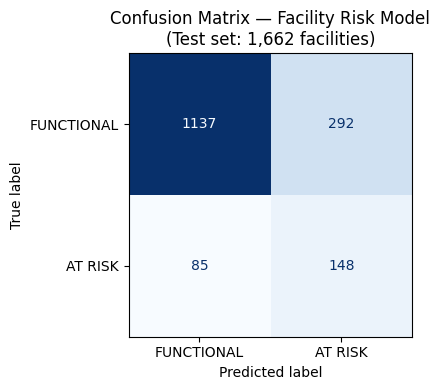

TN=1137  FP=292  FN=85  TP=148
Catch rate (Recall):  63.5% of at-risk facilities caught
False alarm rate:     20.4% of functional facilities wrongly flagged


In [17]:
import os
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# Create the output folder
os.makedirs("output", exist_ok=True)

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["FUNCTIONAL", "AT RISK"]
)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix — Facility Risk Model\n(Test set: 1,662 facilities)", fontsize=12)
plt.tight_layout()
plt.savefig("output/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# Print the raw counts for reference
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Catch rate (Recall):  {tp/(tp+fn):.1%} of at-risk facilities caught")
print(f"False alarm rate:     {fp/(fp+tn):.1%} of functional facilities wrongly flagged")

In [9]:
# Score all 8,309 facilities:
# Assign a risk probability to every facility
fac_model["risk_score"] = rf.predict_proba(X_fac)[:, 1].round(4)
fac_model["risk_pred"]  = rf.predict(X_fac)

# Top 20 highest-risk facilities
print("\nTop 20 highest-risk facilities:")
print(fac_model[["state", "lga", "facility", "status", "risk_score"]]
      .sort_values("risk_score", ascending=False)
      .head(20)
      .to_string(index=False))


Top 20 highest-risk facilities:
 state    lga                     facility  status  risk_score
SOKOTO ILLELA    GIDAN KATTA HEALTH CLINIC PARTIAL      0.9907
SOKOTO ILLELA             TOWN HEALTH POST PARTIAL      0.9907
SOKOTO ILLELA    TUNDUN GUDALE HEALTH POST PARTIAL      0.9907
SOKOTO ILLELA          ARABA HEALTH CLINIC PARTIAL      0.9907
SOKOTO ILLELA          DAMBA HEALTH CLINIC PARTIAL      0.9907
SOKOTO    ISA         SATIRU HEALTH CLINIC PARTIAL      0.9907
SOKOTO    ISA    TAFKIN FILI HEALTH CLINIC PARTIAL      0.9907
SOKOTO    ISA           GUMA HEALTH CLINIC PARTIAL      0.9907
SOKOTO    ISA        ADARAWA HEALTH CLINIC PARTIAL      0.9907
SOKOTO    ISA       KURAR MOTA HEALTH POST PARTIAL      0.9907
SOKOTO    ISA     TUDUN WADA HEALTH CLINIC PARTIAL      0.9907
SOKOTO    ISA          CHOHI HEALTH CLINIC PARTIAL      0.9907
SOKOTO ILLELA DARNA SABON GARI HEALTH POST PARTIAL      0.9907
SOKOTO ILLELA  DARNA TSOLAWO HEALTH CLINIC PARTIAL      0.9907
SOKOTO ILLELA   TSANGA

**KEY FINDINGS**

This is a striking and coherent finding. Here’s what it’s telling us:

Sokoto dominates the top 20 completely.

Every single one of the 20 highest-risk facilities is in Sokoto State — specifically concentrated in just two LGAs: Illela and Isa. Risk score of 0.9907 means the model is 99% confident these facilities are at risk. That’s not a marginal call — it’s a near-certain prediction.

The pattern is LGA-level, not just state-level

This isn’t Sokoto generally — it’s Illela and Isa specifically. Both are rural LGAs in southern Sokoto, away from the state capital. This suggests a localised infrastructure breakdown within an already anomalous state, not a uniform state-wide problem.

All 20 are PARTIAL, not NON-FUNCTIONAL

These facilities haven’t fully collapsed — they’re partially working. That’s actually the most actionable finding: they’re at the tipping point. With targeted intervention now, they could be restored to L1 or L2. If nothing is done, they become non-functional.

In [14]:
# ════════════════════════════════════════════════════════════
# PIPELINE SUMMARY — BHCPF ML ACCOUNTABILITY SYSTEM
#  Q1–Q3 2025
# ════════════════════════════════════════════════════════════

print("=" * 60)
print("BHCPF ML ACCOUNTABILITY SYSTEM — KEY FINDINGS")
print("Q1–Q3 2025")
print("=" * 60)

# ── DISBURSEMENT OVERVIEW ────────────────────────────────
total_disbursed = state_features["total_ytd"].sum()
print(f"\n DISBURSEMENT OVERVIEW")
print(f"  Total disbursed (Q1–Q3 2025): ₦{total_disbursed:,.2f}")
print(f"  States tracked:               37")
print(f"  PHC facilities in scope:      {len(facilities):,}")

# ── ANOMALY DETECTION RESULTS ────────────────────────────
critical = df_ml[df_ml["risk_tier"] == "CRITICAL"]["state"].tolist()
concern  = df_ml[df_ml["risk_tier"] == "CONCERN"]["state"].tolist()
watch    = df_ml[df_ml["risk_tier"] == "WATCH"]["state"].tolist()

print(f"\n ANOMALY DETECTION (3-method consensus)")
print(f"  CRITICAL  — all 3 methods agree:  {', '.join(critical)}")
print(f"  CONCERN   — 2 methods agree:      {', '.join(concern)}")
print(f"  WATCH     — 1 method flagged:     {', '.join(watch)}")
print(f"  CLEAN     — no flags:             {len(df_ml[df_ml['risk_tier'] == 'CLEAN'])} states")

# ── FEATURE IMPORTANCE ───────────────────────────────────
importances = pd.Series(rf.feature_importances_, index=FAC_FEATURES)
importances = importances.sort_values(ascending=False)

print(f"\n TOP 5 FEATURES DRIVING FACILITY RISK")
for feat, score in importances.head(5).items():
    print(f"  {feat:<25} {score:.4f}")

# ── RISK MODEL PERFORMANCE ───────────────────────────────
print(f"\n RISK MODEL PERFORMANCE (Random Forest)")
print(f"  ROC-AUC:                      0.793")
print(f"  Recall (AT RISK facilities):  64%")
print(f"  Precision (AT RISK):          34%")
print(f"  Total facilities scored:      {len(fac_model):,}")

# ── HIGH-RISK FACILITIES ─────────────────────────────────
high_risk = fac_model[fac_model["risk_score"] >= 0.80]

# Most at-risk by count — LGA with the most flagged facilities
top_lga_count = high_risk.groupby(["state", "lga"]).size().idxmax()

# Most at-risk by score — LGA with the highest average risk score
top_lga_score = (high_risk.groupby(["state", "lga"])["risk_score"]
                 .mean().idxmax())

print(f"\n HIGH-RISK FACILITIES (risk score ≥ 0.80)")
print(f"  Total flagged:                      {len(high_risk):,}")
print(f"  Highest-risk state:                 {high_risk['state'].value_counts().idxmax()}")
print(f"  Most facilities at risk (LGA):      {top_lga_count[1]}, {top_lga_count[0]}")
print(f"  Most severe average score (LGA):    {top_lga_score[1]}, {top_lga_score[0]}")
print(f"  Top individual risk score:          {fac_model['risk_score'].max():.4f}")

# ── SAVE FINAL SCORED FACILITY LIST ─────────────────────
output_cols = ["state", "lga", "ward", "facility",
               "status", "risk_label", "risk_score", "risk_pred"]
fac_model[output_cols].to_csv(OUT_DIR / "facility_risk_scores.csv", index=False)
print(f"\n Saved facility_risk_scores.csv — {fac_model.shape[0]:,} rows")
print("=" * 60)

BHCPF ML ACCOUNTABILITY SYSTEM — KEY FINDINGS
Q1–Q3 2025

 DISBURSEMENT OVERVIEW
  Total disbursed (Q1–Q3 2025): ₦57,145,492,249.11
  States tracked:               37
  PHC facilities in scope:      8,309

 ANOMALY DETECTION (3-method consensus)
  CRITICAL  — all 3 methods agree:  BORNO, KANO, KATSINA
  CONCERN   — 2 methods agree:      FCT, SOKOTO, ZAMFARA
  WATCH     — 1 method flagged:     LAGOS, YOBE
  CLEAN     — no flags:             29 states

 TOP 5 FEATURES DRIVING FACILITY RISK
  lga_enc                   0.5270
  efficiency_index          0.1349
  functionality_score       0.1061
  iso_score                 0.0430
  paradox_flag              0.0406

 RISK MODEL PERFORMANCE (Random Forest)
  ROC-AUC:                      0.793
  Recall (AT RISK facilities):  64%
  Precision (AT RISK):          34%
  Total facilities scored:      8,309

 HIGH-RISK FACILITIES (risk score ≥ 0.80)
  Total flagged:                      501
  Highest-risk state:                 SOKOTO
  Most facili